In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler

In [6]:
dataset1 = pd.read_csv('data.csv')
X=dataset1[["Input"]].values
y=dataset1[["Output"]].values

In [21]:
dataset1

,Input,Output
0,1,5
1,2,9
2,3,14
3,4,18
4,5,23
5,6,27
6,7,32
7,8,36
8,9,41
9,10,45


In [7]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.33, random_state=33)

In [8]:
scaler = MinMaxScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [9]:
X_train_tensor = torch.tensor(X_train, dtype=torch.float32)
y_train_tensor = torch.tensor(y_train, dtype=torch.float32).view(-1, 1)
X_test_tensor = torch.tensor(X_test, dtype=torch.float32)
y_test_tensor = torch.tensor(y_test, dtype=torch.float32).view(-1, 1)

In [10]:
# Name: Bharath Raj P
# Register Number: 212223230031
class NeuralNet(nn.Module):
  def __init__(self):
        super().__init__()
        self.fc1=nn.Linear(1,8)
        self.fc2=nn.Linear(8,10)
        self.fc3=nn.Linear(10,1)
        self.relu=nn.ReLU()
        self.history={'loss': []}
  def forward(self,x):
        x=self.relu(self.fc1(x))
        x=self.relu(self.fc2(x))
        x=self.fc3(x)
        return x

In [11]:
# Initialize the Model, Loss Function, and Optimizer
lig=NeuralNet()
criterion=nn.MSELoss()
optimizer=optim.RMSprop(lig.parameters(),lr=0.001)

In [12]:
# Name: Bharath Raj P
# Register Number: 212223230031
def train_model(ai_brain, X_train, y_train, criterion, optimizer, epochs=2000):
    #Include your code here
     for epoch in range (epochs):
        optimizer. zero_grad()
        loss=criterion(ai_brain(X_train), y_train)
        loss. backward()
        optimizer.step()
        lig .history['loss'].append(loss.item())
        if epoch % 200 == 0:
            print(f'Epoch [{epoch}/{epochs}], Loss: {loss.item():.6f}')

In [13]:
train_model(lig, X_train_tensor, y_train_tensor, criterion, optimizer)

Epoch [0/2000], Loss: 1413.432129
Epoch [200/2000], Loss: 1130.348022
Epoch [400/2000], Loss: 682.004639
Epoch [600/2000], Loss: 254.468307
Epoch [800/2000], Loss: 63.740070
Epoch [1000/2000], Loss: 41.518726
Epoch [1200/2000], Loss: 25.543751
Epoch [1400/2000], Loss: 9.698988
Epoch [1600/2000], Loss: 1.361544
Epoch [1800/2000], Loss: 0.069874


In [14]:
with torch.no_grad():
    test_loss = criterion(lig(X_test_tensor), y_test_tensor)
    print(f'Test Loss: {test_loss.item():.6f}')


Test Loss: 1.724618


In [15]:
loss_df = pd.DataFrame(lig.history)

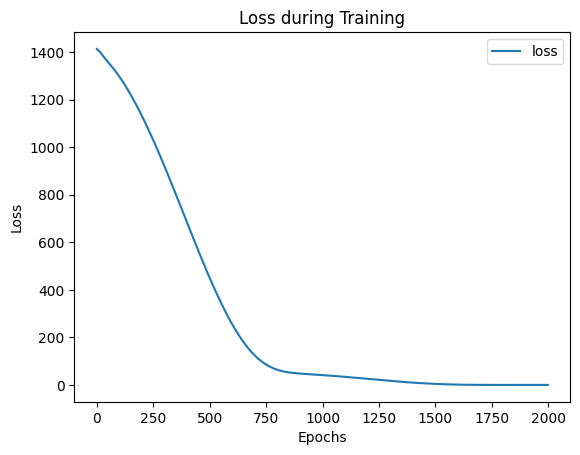

In [16]:
import matplotlib.pyplot as plt
loss_df.plot()
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title("Loss during Training")
plt.show()

In [20]:

X_n1_1 = [16]
scaled_input = scaler.transform([X_n1_1])
prediction = lig(torch.tensor(scaled_input, dtype=torch.float32)).item()
print(f'Prediction: {prediction}')

Prediction: 72.1989974975586
